# 🚀 Lesson 03: Boosting: From AdaBoost to Gradient Boosting

**Time:** ~2.5 hours  **Prerequisites:** Lessons 01–02

Bagging builds its committee **in parallel**: independent trees, averaged. Today's big idea is the opposite:

> **Build the committee *sequentially*. Each new member is trained specifically to fix what the previous members got wrong.**

Think of studying for an exam. You take a practice test, circle every question you missed, and spend your next study session *only* on those. Repeat. Each session is short (a *weak* learner), but together they make you formidable.
That's boosting, and it powers XGBoost, LightGBM and CatBoost, the models that win most tabular-data competitions.

### 🎯 Learning goals
1. Explain the difference between bagging and boosting (variance vs bias, parallel vs sequential).
2. Work **AdaBoost** by hand and implement it from scratch.
3. Derive **gradient boosting** as *gradient descent in function space*; implement it from scratch for squared and absolute loss.
4. Understand and tune **learning rate, number of trees, depth, and subsampling**: and use **early stopping**.
5. Know when boosting is fragile (outliers, noisy labels) and how robust losses help.

In [1]:
import sys; sys.path.append("../utils")          # lets us import the course helpers
from course_utils import *                       # load_housing(), check(), set_style(), ...
import numpy as np, pandas as pd, matplotlib.pyplot as plt

set_style()
np.random.seed(SEED)
from sklearn.tree import DecisionTreeRegressor, DecisionTreeClassifier
from sklearn.ensemble import GradientBoostingRegressor, HistGradientBoostingRegressor, AdaBoostClassifier
from sklearn.datasets import make_moons
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score
from animations import boosting_animation

## 1 · AdaBoost: boosting by re-weighting examples

**AdaBoost** (Freund & Schapire, 1997) was the first practical boosting algorithm. Setting: binary classification with labels $y_i \in \{-1,+1\}$ and **decision stumps** (trees of depth 1) as weak learners.

**The algorithm**
1. Give every training example equal weight $w_i = 1/n$.
2. For rounds $t=1,\dots,T$:
   1. Train a weak learner $h_t$ on the *weighted* data.
   2. Compute its weighted error $\varepsilon_t = \sum_i w_i\,\mathbb 1[h_t(x_i)\neq y_i]$.
   3. Give it a **say** $\alpha_t = \tfrac12 \ln\frac{1-\varepsilon_t}{\varepsilon_t}$: accurate learners (small $\varepsilon$) get a big say; a coin-flip learner ($\varepsilon=\tfrac12$) gets zero.
   4. **Re-weight:** $w_i \leftarrow w_i\,e^{-\alpha_t y_i h_t(x_i)}$, then normalise so the weights sum to 1. *Mistakes get heavier; correct examples get lighter.*
3. Final prediction: $H(x) = \operatorname{sign}\big(\sum_t \alpha_t h_t(x)\big)$: a **weighted vote**.

### 🧪 Worked Example 3.1: one AdaBoost round, by hand

Ten examples, all weight $0.1$. Our first stump misclassifies **3** of them.

* $\varepsilon_1 = 3 \times 0.1 = 0.3$
* $\alpha_1 = \tfrac12\ln(0.7/0.3) = \tfrac12 \ln 2.333 \approx 0.4236$
* Misclassified: $0.1 \cdot e^{+0.4236} = 0.1528$. Correct: $0.1 \cdot e^{-0.4236} = 0.0655$.
* Sum $=3(0.1528)+7(0.0655)=0.9165$ → normalise.

Let the computer do the arithmetic and look for something beautiful:

In [2]:
n = 10
w = np.full(n, 1 / n)
wrong = np.array([False, False, True, False, False, True, False, False, True, False])   # 3 mistakes

eps = w[wrong].sum()
alpha = 0.5 * np.log((1 - eps) / eps)
w_new = w * np.exp(np.where(wrong, +alpha, -alpha))     # mistakes up, correct down
w_new /= w_new.sum()

print(f"weighted error  eps   = {eps:.3f}")
print(f"stump's say     alpha = {alpha:.4f}")
print("new weights:", np.round(w_new, 4))
print(f"total weight on the 3 previously-misclassified points: {w_new[wrong].sum():.4f}")

weighted error  eps   = 0.300
stump's say     alpha = 0.4236
new weights: [0.0714 0.0714 0.1667 0.0714 0.0714 0.1667 0.0714 0.0714 0.1667 0.0714]
total weight on the 3 previously-misclassified points: 0.5000


**Look at the last line: exactly 0.5.** After every AdaBoost round, the examples the last stump got wrong carry **half** of the total weight. So the next stump faces a task on which the previous one is *no better than a coin flip*: it is **forced to learn something new**. That's the engine of the algorithm.

### Implementing AdaBoost from scratch

In [3]:
class MyAdaBoost:
    """Binary AdaBoost with decision stumps (labels 0/1 in, converted to -1/+1 inside)."""

    def __init__(self, n_estimators=50):
        self.n_estimators = n_estimators

    def fit(self, X, y):
        y_pm = np.where(np.asarray(y) == 1, 1, -1)
        n = len(y_pm)
        w = np.full(n, 1 / n)
        self.stumps_, self.alphas_, self.weight_history_ = [], [], [w.copy()]
        for _ in range(self.n_estimators):
            stump = DecisionTreeClassifier(max_depth=1).fit(X, y_pm, sample_weight=w)    # train on WEIGHTED data
            pred = stump.predict(X)
            err = np.clip(w[pred != y_pm].sum(), 1e-10, 1 - 1e-10)                       # weighted error
            alpha = 0.5 * np.log((1 - err) / err)                                          # the stump's "say"
            w = w * np.exp(-alpha * y_pm * pred)                                           # mistakes get heavier
            w = w / w.sum()
            self.stumps_.append(stump); self.alphas_.append(alpha); self.weight_history_.append(w.copy())
        return self

    def decision_function(self, X, n=None):
        n = n or self.n_estimators
        return sum(a * s.predict(X) for a, s in zip(self.alphas_[:n], self.stumps_[:n]))

    def predict(self, X, n=None):
        return (self.decision_function(X, n) > 0).astype(int)

class Stage:                                                   # tiny wrapper: "the ensemble after k rounds"
    def __init__(self, model, k): self.model, self.k = model, k
    def predict(self, X): return self.model.predict(X, self.k)

Let's watch it learn on the noisy two-moons data. In the top row the **size of each dot is its current weight**; in the bottom row we see the ensemble's decision regions as stumps accumulate.
🔮 *Which dots will be biggest after a few rounds?*

In [4]:
Xm, ym = make_moons(n_samples=300, noise=0.28, random_state=3)
Xm_train, Xm_test, ym_train, ym_test = train_test_split(Xm, ym, test_size=0.4, random_state=1)
ada = MyAdaBoost(n_estimators=100).fit(Xm_train, ym_train)

fig, axes = plt.subplots(2, 4, figsize=(15, 7))
for ax, t in zip(axes[0], [0, 1, 3, 10]):
    wts = ada.weight_history_[t]
    ax.scatter(*Xm_train.T, s=wts / wts.max() * 220 + 6, c=np.where(ym_train == 1, PALETTE["orange"], PALETTE["blue"]), alpha=.7, edgecolor="white")
    ax.set_title(f"weights before round {t + 1}"); ax.set_xticks([]); ax.set_yticks([]); ax.grid(False)
for ax, k in zip(axes[1], [1, 5, 25, 100]):
    acc = accuracy_score(ym_test, ada.predict(Xm_test, k))
    plot_decision_boundary(Stage(ada, k), Xm_train, ym_train, ax=ax, title=f"{k} stump{'s' if k > 1 else ''}: test acc {acc:.0%}")
plt.tight_layout(); plt.show()

sk_ada = AdaBoostClassifier(n_estimators=100, random_state=0).fit(Xm_train, ym_train)
print(f"our AdaBoost: {accuracy_score(ym_test, ada.predict(Xm_test)):.1%}   |   scikit-learn AdaBoost: {accuracy_score(ym_test, sk_ada.predict(Xm_test)):.1%}")

our AdaBoost: 86.7%   |   scikit-learn AdaBoost: 86.7%


**What to notice.**
* A *single stump* is one straight line: hopeless for a curved boundary (**high bias**). A hundred stumps trace a smooth S-curve. Boosting **reduces bias**: it builds a flexible model out of simple, rigid pieces.
* The big dots after round 1 are the points the first stump got wrong; the algorithm keeps pushing attention to the stubborn ones.
* ⚠️ That last point is also AdaBoost's weakness: **mislabeled or noisy points keep gaining weight**, and the algorithm contorts itself to fit them. Keep this in mind for Section 6.

## 2 · Gradient Boosting: the big generalisation

AdaBoost re-weights *examples*. **Gradient boosting** (Friedman, 2001) re-thinks the process as an *optimisation*, which makes it work for **any differentiable loss**: regression, classification, ranking.

### The recipe (squared-error regression)
1. Start with a constant prediction: $F_0(x) = \bar y$.
2. For $m = 1, \dots, M$:
   1. Compute the **residuals** $r_i = y_i - F_{m-1}(x_i)$: what we still get wrong.
   2. Fit a small tree $h_m$ to predict those residuals from $x$.
   3. Update: $F_m(x) = F_{m-1}(x) + \nu\,h_m(x)$, where $\nu\in(0,1]$ is the **learning rate**.

Each tree is a small correction to the current guess. Add up many corrections and the prediction converges toward $y$.

### 🧪 Worked Example 3.2: two rounds on five houses (by hand!)

| house | 1 | 2 | 3 | 4 | 5 |
|---|---|---|---|---|---|
| size (x) | 1 | 2 | 3 | 4 | 5 |
| price y | 10 | 12 | 11 | 20 | 23 |

**Round 0.** $F_0 = \bar y = 15.2$. Residuals: $r = (-5.2,\,-3.2,\,-4.2,\,+4.8,\,+7.8)$.  
**Round 1.** A stump splits between houses 3 and 4. Left leaf predicts the mean residual $(-5.2-3.2-4.2)/3 = -4.2$; right leaf $(4.8+7.8)/2 = +6.3$.
With $\nu = 0.5$: $F_1 = 15.2 + 0.5\cdot(-4.2) = 13.1$ for houses 1–3 and $15.2+0.5\cdot 6.3 = 18.35$ for houses 4–5.  
New residuals: $y - F_1 = (-3.1,\,-1.1,\,-2.1,\,+1.65,\,+4.65)$: **smaller in magnitude**. ✔️ Let the machine confirm and continue for a few more rounds:

In [5]:
x5 = np.array([[1], [2], [3], [4], [5]]); y5 = np.array([10., 12, 11, 20, 23])
nu = 0.5
F = np.full(5, y5.mean())
print(f"round 0: F = {F},  residuals = {np.round(y5 - F, 2)}")
for m in range(1, 5):
    resid = y5 - F
    stump = DecisionTreeRegressor(max_depth=1).fit(x5, resid)
    F = F + nu * stump.predict(x5)
    print(f"round {m}: F = {np.round(F, 2)},  residuals = {np.round(y5 - F, 2)}   (sum of squared residuals = {np.sum((y5 - F) ** 2):.2f})")

round 0: F = [15.2 15.2 15.2 15.2 15.2],  residuals = [-5.2 -3.2 -4.2  4.8  7.8]
round 1: F = [13.1  13.1  13.1  18.35 18.35],  residuals = [-3.1  -1.1  -2.1   1.65  4.65]   (sum of squared residuals = 39.57)
round 2: F = [12.05 12.05 12.05 19.92 19.92],  residuals = [-2.05 -0.05 -1.05  0.07  3.07]   (sum of squared residuals = 14.77)
round 3: F = [11.67 11.67 11.67 19.54 21.46],  residuals = [-1.67  0.33 -0.67  0.46  1.54]   (sum of squared residuals = 5.90)
round 4: F = [10.83 11.87 11.87 19.75 21.67],  residuals = [-0.83  0.13 -0.87  0.25  1.33]   (sum of squared residuals = 3.30)


Round 1 matches our hand calculation, and the sum of squared residuals shrinks every round. We're sliding downhill.

### Why is it called *gradient* boosting?

Take the squared-error loss for one example, $L(y, F) = \tfrac12 (y - F)^2$. Its derivative with respect to the *prediction* $F$ is

$$\frac{\partial L}{\partial F} = -(y - F) \quad\Longrightarrow\quad -\frac{\partial L}{\partial F} = y - F = \text{residual!}$$

So **fitting a tree to the residuals is fitting it to the negative gradient of the loss.** Adding $\nu h_m$ is one step of *gradient descent*: not in parameter space, but in **function space**: we nudge the whole prediction function in the direction that reduces the loss fastest, and we use a tree to *represent* that direction (it generalises the nudge from training points to unseen $x$).

Now the punchline: **other losses just change the "pseudo-residual".**

| loss | $L(y,F)$ | pseudo-residual $-\partial L/\partial F$ | leaf value (best constant) |
|---|---|---|---|
| squared error | $\frac12(y-F)^2$ | $y - F$ | mean of residuals in leaf |
| absolute error | $\lvert y - F\rvert$ | $\operatorname{sign}(y - F)$ | **median** of residuals in leaf |
| Huber | quadratic near 0, linear far | clipped residual | between the two |
| log-loss (classification) | $-y\ln p-(1-y)\ln(1-p)$ | $y - p$ | Newton-step formula (Lesson 04) |

One algorithm, many problems. Let's implement it (for squared **and** absolute loss) in about 40 lines.

In [6]:
class MyGradientBoosting:
    """Gradient boosting for regression with squared or absolute loss (trees = small regression trees)."""

    def __init__(self, n_estimators=100, learning_rate=0.1, max_depth=3, loss="squared", subsample=1.0, random_state=0):
        self.n_estimators, self.learning_rate, self.max_depth = n_estimators, learning_rate, max_depth
        self.loss, self.subsample, self.random_state = loss, subsample, random_state

    # --- the three ingredients that depend on the loss -------------------------------------
    def _init(self, y):            return y.mean() if self.loss == "squared" else np.median(y)
    def _pseudo_resid(self, y, F): return (y - F) if self.loss == "squared" else np.sign(y - F)
    def _leaf_value(self, resid):  return resid.mean() if self.loss == "squared" else np.median(resid)

    def fit(self, X, y):
        rng = np.random.default_rng(self.random_state)
        X, y = np.asarray(X, float), np.asarray(y, float)
        n = len(y)
        self.f0_ = self._init(y)
        F = np.full(n, self.f0_)
        self.trees_, self.leaf_tables_ = [], []
        for m in range(self.n_estimators):
            rows = rng.choice(n, int(self.subsample * n), replace=False) if self.subsample < 1 else np.arange(n)
            tree = DecisionTreeRegressor(max_depth=self.max_depth, random_state=m).fit(X[rows], self._pseudo_resid(y, F)[rows])
            # line search: best constant per leaf for the REAL loss, using the rows this tree was trained on
            leaf_of_row = tree.apply(X[rows])
            table = np.zeros(tree.tree_.node_count)
            for leaf in np.unique(leaf_of_row):
                table[leaf] = self._leaf_value((y - F)[rows][leaf_of_row == leaf])
            F = F + self.learning_rate * table[tree.apply(X)]
            self.trees_.append(tree); self.leaf_tables_.append(table)
        return self

    def staged_predict(self, X):
        """Yield the ensemble's prediction after 1, 2, 3, ... trees (great for learning curves)."""
        X = np.asarray(X, float)
        F = np.full(len(X), self.f0_)
        for tree, table in zip(self.trees_, self.leaf_tables_):
            F = F + self.learning_rate * table[tree.apply(X)]
            yield F.copy()

    def predict(self, X):
        for F in self.staged_predict(X):
            pass
        return F

Let's see it in action on a noisy wave, then *watch it learn* in the animation below (left: the ensemble's fit after each tree; right: the residuals the next tree is asked to fix: they shrink toward pure noise).

In [7]:
rng = np.random.default_rng(0)
xs = np.sort(rng.uniform(0, 2 * np.pi, 120))[:, None]
ys = np.sin(xs[:, 0]) + 0.3 * np.sin(3 * xs[:, 0]) + rng.normal(0, 0.15, 120)
grid = np.linspace(0, 2 * np.pi, 400)[:, None]

fig, axes = plt.subplots(1, 5, figsize=(17, 3.4), sharey=True)
for ax, M in zip(axes, [1, 3, 10, 40, 200]):
    gb = MyGradientBoosting(n_estimators=M, learning_rate=0.3, max_depth=2).fit(xs, ys)
    ax.scatter(xs, ys, s=8, color=PALETTE["gray"]); ax.plot(grid, gb.predict(grid), color=PALETTE["blue"], lw=2.5)
    ax.set_title(f"{M} tree{'s' if M > 1 else ''}")
plt.tight_layout(); plt.show()

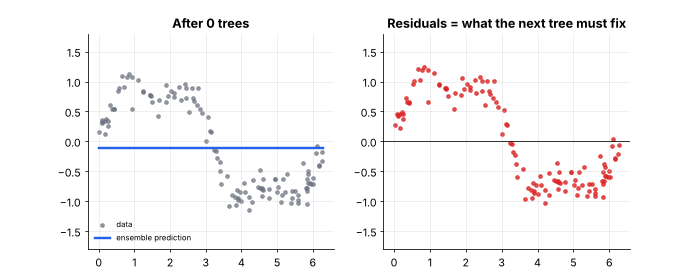

In [8]:
show_gif(boosting_animation())

**Notice the stages.** One tree: a crude 4-step staircase (high bias). After 40: it follows the wave. After 200: it has started to chase noise (variance creeping in). Boosting moves along the **bias → variance** axis as you add trees, so the number of trees is a genuine *overfitting* knob: unlike in a random forest.

### Does our implementation agree with scikit-learn?
Let's check on the housing data (same depth, learning rate, number of trees).

In [9]:
X_train, X_test, y_train, y_test = get_housing_split()
prep = make_preprocessor(X_train)
Xtr, Xte = prep.fit_transform(X_train), prep.transform(X_test)
def rmse(y, p): return float(np.sqrt(np.mean((np.asarray(y) - np.asarray(p)) ** 2)))

with Timer() as t_mine:
    mine = MyGradientBoosting(n_estimators=200, learning_rate=0.1, max_depth=3).fit(Xtr, y_train)
with Timer() as t_sk:
    sk = GradientBoostingRegressor(n_estimators=200, learning_rate=0.1, max_depth=3, random_state=SEED).fit(Xtr, y_train)

pd.DataFrame({"model": ["Our gradient boosting", "scikit-learn GradientBoostingRegressor"],
              "test RMSE": [rmse(y_test, mine.predict(Xte)), rmse(y_test, sk.predict(Xte))],
              "fit seconds": [t_mine.seconds, t_sk.seconds]}).round(2)

,model,test RMSE,fit seconds
0,Our gradient boosting,105.51,0.97
1,scikit-learn GradientBoostingRegressor,105.40,0.76


Very close: differences come from tie-breaking in splits and scikit-learn's tree criterion. You now **understand what's inside a gradient boosting machine**; everything else in this course is engineering on top.

## 3 · The learning rate × number of trees trade-off

Each tree's contribution is multiplied by the learning rate (also called **shrinkage**) $\nu$. Small $\nu$ = small cautious steps.

🔮 **Predict:** for $\nu = 1.0, 0.3, 0.1, 0.03$, which learning rate reaches the lowest test error *eventually*? Which reaches a decent error fastest? Which overfits first?

In [10]:
curves, best = {}, {}
for lr in [1.0, 0.3, 0.1, 0.03]:
    gbr = GradientBoostingRegressor(n_estimators=800, learning_rate=lr, max_depth=3, random_state=SEED).fit(Xtr, y_train)
    curves[lr] = np.array([rmse(y_test, p) for p in gbr.staged_predict(Xte)])
    best[lr] = (int(curves[lr].argmin()) + 1, curves[lr].min())

plt.figure(figsize=(9, 4.5))
for lr, c in curves.items():
    plt.plot(np.arange(1, 801), c, label=f"learning rate {lr}  (best: {best[lr][1]:.1f} at {best[lr][0]} trees)")
plt.ylim(95, 200); plt.xlabel("number of trees"); plt.ylabel("test RMSE"); plt.legend()
plt.title("Smaller steps → need more trees → usually a better optimum"); plt.show()

### 🔎 What the curves say
* **ν = 1.0:** drops fast, bottoms out after only ~20 trees at RMSE ≈ 142, then *rises* (≈ 164 by 800 trees): it overfits quickly and its best score is the worst.
* **ν = 0.03:** needs hundreds of trees (it is *still improving* at 800, RMSE ≈ 101) but reaches the **lowest error**: small steps explore the landscape more carefully.
* Notice each curve has a **minimum, then climbs** (or flattens): that's overfitting. The fix is **early stopping**: stop adding trees when validation error stops improving.

> 💡 **The professional's rule:** *set the learning rate small (0.01–0.1), set n_estimators generously high, and let early stopping pick the number of trees.* Halve the rate → roughly double the trees needed.

## 4 · The other knobs

| hyperparameter | typical range | effect |
|---|---|---|
| `max_depth` (tree depth) | 2–8 | **= interaction order.** depth 1 ⇒ purely additive model; depth 3 ⇒ up to 3-way interactions |
| `subsample` | 0.5–1.0 | **stochastic gradient boosting**: each tree sees a random fraction of rows → more diversity, regularisation, speed |
| `min_samples_leaf` | 1–50 | bigger leaves → smoother, less overfit |
| `max_features` | 0.3–1.0 | random feature subset per split (borrowed from random forests) |
| `n_iter_no_change` + `validation_fraction` | - | built-in early stopping |

The depth row deserves an experiment. A depth-1 boosted model is $F(x) = \sum_j f_j(x_j)$ (each feature contributes *separately*. Real prices have interactions (size matters more in prime neighbourhoods), so deeper trees should help) up to a point.

In [11]:
rows = []
for depth in [1, 2, 3, 4, 6, 8]:
    gbr = GradientBoostingRegressor(n_estimators=400, learning_rate=0.05, max_depth=depth, random_state=SEED).fit(Xtr, y_train)
    staged = np.array([rmse(y_test, p) for p in gbr.staged_predict(Xte)])
    rows.append({"max_depth": depth, "best test RMSE": staged.min(), "at n_trees": int(staged.argmin()) + 1, "final (400 trees)": staged[-1]})
depth_table = pd.DataFrame(rows)
depth_table.round(1)

,max_depth,best test RMSE,at n_trees,final (400 trees)
0,1,158.6,400,158.6
1,2,107.0,399,107.1
2,3,102.2,379,102.3
3,4,104.6,380,104.6
4,6,99.7,363,99.7
5,8,122.5,393,122.5


Depth 1 (an additive model, RMSE ≈ 159) is clearly worse: it can't represent interactions. The best depths here are modest (3–6); **very deep** boosted trees overfit and mostly lose their advantage.
That's why boosting uses **shallow** trees (weak learners!) whereas bagging wants **deep** ones: bagging fixes variance, so it needs low-bias members; boosting fixes bias, so it's fine to start with high-bias members.

### Stochastic gradient boosting + built-in early stopping
Subsampling rows (like bagging, inside boosting) often helps a little and speeds things up. And scikit-learn can stop automatically:

In [12]:
gbr_es = GradientBoostingRegressor(
    n_estimators=3000, learning_rate=0.05, max_depth=4, subsample=0.7,
    validation_fraction=0.15, n_iter_no_change=30, tol=1e-4, random_state=SEED,
).fit(Xtr, y_train)

print(f"asked for 3000 trees, early stopping kept {gbr_es.n_estimators_}")
print(f"test RMSE: {rmse(y_test, gbr_es.predict(Xte)):.1f}")

asked for 3000 trees, early stopping kept 301
test RMSE: 102.6


## 5 · Histogram-based gradient boosting (a sneak peek at the modern libraries)

Classic gradient boosting searches every possible split threshold of every feature. **Histogram-based** boosting first *bins* each feature into ≤255 buckets and searches only the bucket boundaries: dramatically faster on big data, with almost no loss in accuracy.
This is the trick behind LightGBM (Lesson 04), and scikit-learn ships it as `HistGradientBoostingRegressor`. As a bonus it handles **missing values and categorical features natively**, so no imputing or one-hot encoding is needed:

In [13]:
Xtr_raw, Xte_raw = X_train.copy(), X_test.copy()
for c in HOUSING_CATEGORICAL:                                   # category dtype = "this column is categorical"
    cats = sorted(Xtr_raw[c].dropna().unique())
    Xtr_raw[c] = pd.Categorical(Xtr_raw[c], categories=cats)
    Xte_raw[c] = pd.Categorical(Xte_raw[c], categories=cats)

with Timer() as t_h:
    hgb = HistGradientBoostingRegressor(learning_rate=0.05, max_iter=400, max_depth=4, categorical_features="from_dtype",
                                        early_stopping=False, random_state=SEED).fit(Xtr_raw, y_train)   # raw data, NaNs and all!
print(f"HistGradientBoosting on RAW data (NaNs + categoricals untouched): test RMSE = {rmse(y_test, hgb.predict(Xte_raw)):.1f}   fit time = {t_h.seconds:.1f}s")

HistGradientBoosting on RAW data (NaNs + categoricals untouched): test RMSE = 89.4   fit time = 0.3s


Even with **no preprocessing at all**, the histogram model lands at the front of the pack here (RMSE ≈ 89 vs ≈ 102–105 for the classic implementations, in a third of the time). Part of the credit goes to its *native* handling of categoricals: treating `neighborhood` as a genuine category (instead of 12 one-hot columns) lets a single split group neighbourhoods by their price level.
Hold that thought for Lesson 04, where all three modern libraries compete.

## 6 · Boosting's Achilles heel: outliers and noisy labels

Boosting works by chasing residuals. A huge outlier has a huge residual, so *every* subsequent tree is tempted to chase it. Squared loss makes this worse (errors are squared!).
**Robust losses** (absolute, Huber) cap the pull of any single point. Experiment: a sine wave with 8% corrupted labels (+4 units).

In [14]:
rng = np.random.default_rng(5)
xo = rng.uniform(0, 2 * np.pi, 300)
y_clean = np.sin(xo)
yo = y_clean + rng.normal(0, 0.15, 300)
bad = rng.random(300) < 0.08
yo[bad] += 4.0                                               # 8% corrupted labels
Xo = xo[:, None]; Xo_grid = np.linspace(0, 2 * np.pi, 300)[:, None]

gb_sq = MyGradientBoosting(n_estimators=150, learning_rate=0.1, max_depth=2, loss="squared").fit(Xo, yo)
gb_abs = MyGradientBoosting(n_estimators=150, learning_rate=0.1, max_depth=2, loss="absolute").fit(Xo, yo)

plt.figure(figsize=(8.5, 4.4))
plt.scatter(xo, yo, s=10, color=PALETTE["gray"], label="training data (with outliers)")
plt.plot(Xo_grid, np.sin(Xo_grid), "k--", label="truth")
plt.plot(Xo_grid, gb_sq.predict(Xo_grid), color=PALETTE["red"], lw=2, label="squared loss")
plt.plot(Xo_grid, gb_abs.predict(Xo_grid), color=PALETTE["green"], lw=2, label="absolute loss")
plt.legend(loc="upper right"); plt.title("Robust loss ignores outliers; squared loss chases them"); plt.show()

The red curve (squared loss) develops bumps wherever outliers cluster; the green curve (absolute loss) stays close to the truth. Practical consequences:

* If your target has heavy tails or data-entry errors (like our housing prices, which include a few ×2 "mansions"), consider `loss="absolute_error"`/`"huber"`, or model `log(price)`.
* In AdaBoost the same failure shows up as label-noise sensitivity (Section 1).

## 7 · Bagging vs. boosting: the comparison to memorise

| | **Bagging / Random Forest** | **Boosting** |
|---|---|---|
| Training | **parallel**, independent trees | **sequential**, each tree depends on the last |
| Base learner | deep, low-bias/high-variance trees | shallow, high-bias trees |
| Mainly reduces | **variance** | **bias** (and some variance) |
| Overfitting with more trees? | No (plateaus) | **Yes**: needs early stopping |
| Sensitivity to noise/outliers | Low | Higher (use robust loss, regularise) |
| Tuning effort | Low (good defaults | Higher) learning rate, depth, trees, subsample… |
| Typical accuracy ceiling | Very good | **Best on most tabular problems** |
| Parallelism | Trivial | Within a tree only |

**Next lesson:** *how* do XGBoost, LightGBM and CatBoost take this recipe and make it fast, regularised, and accurate?

### ✋ Check your understanding

Try to answer *out loud* before you open the answer. If you can't say it simply, you don't own it yet.

**Q1. Why does AdaBoost use *stumps* instead of deep trees?**

<details><summary>Show answer</summary>

Boosting reduces **bias**: it needs weak, high-bias learners that can be combined into a flexible model. Deep trees would fit the training data almost perfectly in the first round (leaving no mistakes to focus on) and overfit.

</details>

**Q2. You change the learning rate from 0.1 to 0.05. What should you do with n_estimators, and why?**

<details><summary>Show answer</summary>

Roughly **double it**. Each tree now contributes half as much, so you need about twice as many steps to travel the same distance. In practice: set a generous n_estimators and use early stopping.

</details>

**Q3. What *is* the 'gradient' in gradient boosting (squared-error case)?**

<details><summary>Show answer</summary>

The negative derivative of the loss with respect to the current prediction, $-\partial L/\partial F = y - F$: the residual. Each tree is trained to approximate that direction of steepest descent in function space.

</details>

**Q4. Why is gradient boosting with squared loss more sensitive to outliers than a random forest?**

<details><summary>Show answer</summary>

Boosting repeatedly focuses on points with large residuals, and squared loss amplifies big residuals, so one outlier can drag many successive trees. A random forest averages independent trees: an outlier influences only the ~63% of trees that sampled it, and each of those trees is just one vote.

</details>

**Q5. Depth-1 boosted trees are an *additive* model. What does that mean and when would it be enough?**

<details><summary>Show answer</summary>

The prediction is $\sum_j f_j(x_j)$: each feature contributes independently, with no interactions. It's enough when the true relationship has no (important) interactions, and it's very interpretable. If effects depend on each other (size × neighbourhood), you need depth ≥ 2.

</details>

## 8 · Problems

### 🧩 Problem 03.1 ⭐: One AdaBoost round

Ten examples start with equal weights. A stump misclassifies **2** of them (weighted error ε = 0.2).

Compute, with NumPy:
* `alpha`: the stump's say, $\tfrac12\ln\frac{1-\varepsilon}{\varepsilon}$
* `w_mis` and `w_ok`: the **normalised** new weight of *each* misclassified and *each* correctly-classified example

*Sanity check to make on paper:* what must the total weight of the two misclassified points be?

<details><summary>💡 Hint 1</summary>

Start with `w = np.full(10, 0.1)`; the first two entries are the mistakes.

</details>

<details><summary>💡 Hint 2</summary>

Unnormalised: mistakes `0.1 * np.exp(alpha)`, correct `0.1 * np.exp(-alpha)`. Normalise by dividing by the sum over all ten.

</details>

<details><summary>💡 Hint 3</summary>

You should get `w_mis = 0.25` and `w_ok = 0.0625`: and 2 × 0.25 = 0.5, as always.

</details>

<details><summary>🆘 Stuck for real? Read this</summary>

Walk away for five minutes, re-read the lesson section above, then compare with the solutions notebook of the same name (`../solutions/`). Peeking is allowed -- but *type* the solution yourself, don't paste it.

</details>


In [ ]:
eps = 0.2
alpha = TODO    # YOUR CODE HERE
w_mis = TODO    # YOUR CODE HERE
w_ok = TODO     # YOUR CODE HERE

# ---- self-check (don't edit) ----
check("03.1", lambda: abs(alpha - 0.6931) < 1e-3 and abs(w_mis - 0.25) < 1e-6 and abs(w_ok - 0.0625) < 1e-6,
      "alpha = 0.5*ln(4) ≈ 0.693; normalised weights should be 0.25 and 0.0625.", needs=[alpha, w_mis, w_ok])

### 🧩 Problem 03.2 ⭐⭐: One gradient-boosting step, by code

Using the five-house data (`x5`, `y5`) and learning rate `nu = 0.5`:

1. start from `F0 = y5.mean()` (a vector of 5 identical values) → store `F0`
2. compute the residuals, fit **one** `DecisionTreeRegressor(max_depth=1)` to them, and form `F1 = F0 + nu * stump.predict(x5)` → store `F1`
3. store the new residuals `y5 - F1` in `resid1`

Compare with the numbers we computed by hand in Worked Example 3.2.

<details><summary>💡 Hint 1</summary>

`F0 = np.full(5, y5.mean())`; residuals `r0 = y5 - F0`.

</details>

<details><summary>💡 Hint 2</summary>

`stump = DecisionTreeRegressor(max_depth=1).fit(x5, r0)`; its `.predict(x5)` gives the leaf means (−4.2 and +6.3).

</details>

<details><summary>💡 Hint 3</summary>

`F1 = F0 + nu * stump.predict(x5)` should be `[13.1, 13.1, 13.1, 18.35, 18.35]`.

</details>

<details><summary>🆘 Stuck for real? Read this</summary>

Walk away for five minutes, re-read the lesson section above, then compare with the solutions notebook of the same name (`../solutions/`). Peeking is allowed -- but *type* the solution yourself, don't paste it.

</details>


In [ ]:
nu = 0.5
F0 = TODO       # YOUR CODE HERE
F1 = TODO       # YOUR CODE HERE
resid1 = TODO   # YOUR CODE HERE

# ---- self-check (don't edit) ----
check("03.2", lambda: np.allclose(F1, [13.1, 13.1, 13.1, 18.35, 18.35]) and np.allclose(resid1, [-3.1, -1.1, -2.1, 1.65, 4.65]),
      "F1 should be [13.1, 13.1, 13.1, 18.35, 18.35] and the residuals [-3.1, -1.1, -2.1, 1.65, 4.65].", needs=[F0, F1, resid1])

### 🧩 Problem 03.3 ⭐⭐: Squared vs. absolute loss under label noise

Using the corrupted sine data (`Xo`, `yo`) and the clean truth `np.sin(Xo_grid)`, fit **two** `MyGradientBoosting` models
(`n_estimators=150, learning_rate=0.1, max_depth=2`): one with `loss="squared"`, one with `loss="absolute"`.

Store each model's RMSE **against the clean truth on `Xo_grid`** in `rmse_sq` and `rmse_abs`.
The robust model should win.

<details><summary>💡 Hint 1</summary>

You already fitted similar models in Section 6 (`gb_sq`, `gb_abs`), but write the code yourself, then compare.

</details>

<details><summary>💡 Hint 2</summary>

RMSE against the truth: `np.sqrt(np.mean((model.predict(Xo_grid) - np.sin(Xo_grid[:, 0])) ** 2))`.

</details>

<details><summary>🆘 Stuck for real? Read this</summary>

Walk away for five minutes, re-read the lesson section above, then compare with the solutions notebook of the same name (`../solutions/`). Peeking is allowed -- but *type* the solution yourself, don't paste it.

</details>


In [ ]:
rmse_sq = TODO    # YOUR CODE HERE
rmse_abs = TODO   # YOUR CODE HERE

# ---- self-check (don't edit) ----
check("03.3", lambda: rmse_abs < rmse_sq and rmse_abs < 0.35,
      "The absolute-loss model should be closer to the clean sine wave than the squared-loss model.", needs=[rmse_sq, rmse_abs])

### 🧩 Problem 03.4 ⭐⭐⭐: Find the best number of trees (early stopping by hand)

Split the training data again: `Xa, Xv, ya, yv = train_test_split(Xtr, y_train, test_size=0.2, random_state=SEED)`.

1. Fit `GradientBoostingRegressor(n_estimators=800, learning_rate=0.05, max_depth=3, random_state=SEED)` on `(Xa, ya)`.
2. Use `staged_predict(Xv)` to compute the validation RMSE after every tree. Store the best number of trees in `best_n` (1-based).
3. Refit on **all** of `(Xtr, y_train)` with `n_estimators=best_n` and store the **test RMSE** in `final_test_rmse`.

<details><summary>💡 Hint 1</summary>

`val_curve = [rmse(yv, p) for p in gbr.staged_predict(Xv)]` gives one number per tree.

</details>

<details><summary>💡 Hint 2</summary>

`best_n = int(np.argmin(val_curve)) + 1` (argmin is 0-based!).

</details>

<details><summary>💡 Hint 3</summary>

Refit: `GradientBoostingRegressor(n_estimators=best_n, learning_rate=0.05, max_depth=3, random_state=SEED).fit(Xtr, y_train)` and evaluate on `Xte`.

</details>

<details><summary>🆘 Stuck for real? Read this</summary>

Walk away for five minutes, re-read the lesson section above, then compare with the solutions notebook of the same name (`../solutions/`). Peeking is allowed -- but *type* the solution yourself, don't paste it.

</details>


In [ ]:
Xa, Xv, ya, yv = train_test_split(Xtr, y_train, test_size=0.2, random_state=SEED)

best_n = TODO            # YOUR CODE HERE
final_test_rmse = TODO   # YOUR CODE HERE

# ---- self-check (don't edit) ----
check("03.4", lambda: 50 <= best_n <= 800 and final_test_rmse < 125,
      "best_n should be somewhere in the hundreds; the refit model's test RMSE should be below 125.", needs=[best_n, final_test_rmse])

In [19]:
scoreboard()

Scoreboard: 4 solved, 0 to fix, 0 not attempted
   ✅ 03.1
   ✅ 03.2
   ✅ 03.3
   ✅ 03.4


## 🏁 Recap

* **Boosting** builds models *sequentially*; each one is trained to correct the ensemble so far. It mainly attacks **bias**.
* **AdaBoost** re-weights examples (mistakes ↑) and combines stumps with weights $\alpha_t=\tfrac12\ln\frac{1-\varepsilon_t}{\varepsilon_t}$.
* **Gradient boosting** fits each tree to the **negative gradient** (pseudo-residual) of the loss: gradient descent in function space. Changing the loss changes the pseudo-residual: nothing else.
* **Learning rate × number of trees** trade off: small ν + many trees + **early stopping** is the standard recipe.
* Depth controls the **interaction order**; subsampling adds regularisation; robust losses protect against outliers.

### ➡️ Next up: **Lesson 04: XGBoost, LightGBM, CatBoost**
Same idea, industrial strength: second-order optimisation, built-in regularisation, histogram splits, leaf-wise growth, native categorical handling, and a hand-computed leaf weight that XGBoost reproduces to six decimals.